# 11. Tutorial 11

**Course:** High Switching Frequency Power Converters

## 11.1 SC analyser and charge-multiplier vectors

A two-phase SC converter is described by a netlist: capacitors `(name, node_plus, node_minus)` and switches `(name, node_a, node_b, phase)`; the nodes `'in'`, `'out'` and `'gnd'` connect to ideal sources $V_\mathrm{in}$ and $V_\mathrm{out}$.

11.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt) and create the function `analyse(caps, sw, Vin)` that returns the conversion ratio, $a_\mathrm{c}$, $a_\mathrm{r}$, the capacitor voltages, the switch blocking voltages, $\sum a_\mathrm{c}v_\mathrm{c}$, $\sum a_\mathrm{r}v_\mathrm{r}$, $\sum a_\mathrm{c}^2$ and $2\sum a_\mathrm{r}^2$:
- charges: Kirchhoff's current law at every node in both phases, charge balance of every capacitor, $q_\mathrm{out}^{(1)} + q_\mathrm{out}^{(2)} = 1$;
- voltages: closed switches as shorts, the same capacitor voltage in both phases, fixed input and output potentials.

Solve both linear systems by least squares and check the rank.

11.1.2 Create netlist functions for the $N$:1 series-parallel converter, the 4:1 Dickson, the $N$:1 ladder and two cascaded 2:1 converters. Print the results for the 3:1 series-parallel converter and the four 4:1 converters.


In [1]:
# Subtask 11.1.1 Import necessary modules and create the analyser
import numpy as np
import matplotlib.pyplot as plt


def analyse(caps, sw, Vin=1.0):
    """Charge multipliers (Seeman and Sanders 2008) and ideal voltages of a two-phase SC converter."""
    nodes = sorted({n for c in caps for n in c[1:3]} | {n for s in sw for n in s[1:3]} | {'in', 'out', 'gnd'})
    idx = {n: i for i, n in enumerate(nodes)}
    nc, ns, nn = len(caps), len(sw), len(nodes)
    # charges: q_c(1), q_c(2), q_sw (in its phase), q_in(1), q_in(2), q_out(1), q_out(2)
    nu = 2 * nc + ns + 4
    A, b = [], []
    for ph in (1, 2):
        for n in nodes:
            if n == 'gnd':
                continue
            r = np.zeros(nu)
            for i, (_, p, m) in enumerate(caps):
                if p == n: r[(ph - 1) * nc + i] -= 1
                if m == n: r[(ph - 1) * nc + i] += 1
            for k, (_, a, bb, phs) in enumerate(sw):
                if phs == ph:
                    if a == n: r[2 * nc + k] -= 1
                    if bb == n: r[2 * nc + k] += 1
            if n == 'in': r[2 * nc + ns + ph - 1] += 1
            if n == 'out': r[2 * nc + ns + 2 + ph - 1] -= 1
            A.append(r); b.append(0.0)
    for i in range(nc):
        r = np.zeros(nu); r[i] = r[nc + i] = 1; A.append(r); b.append(0.0)
    r = np.zeros(nu); r[2 * nc + ns + 2] = r[2 * nc + ns + 3] = 1; A.append(r); b.append(1.0)
    q, _, rank, _ = np.linalg.lstsq(np.array(A), np.array(b), rcond=None)
    if rank < nu:
        raise ValueError('charge flow not unique')
    # voltages: node potentials in both phases, capacitor voltages, V_out
    nv = 2 * nn + nc + 1
    A, b = [], []
    for ph in (1, 2):
        o = (ph - 1) * nn
        for n, val in (('gnd', 0.0), ('in', Vin)):
            r = np.zeros(nv); r[o + idx[n]] = 1; A.append(r); b.append(val)
        r = np.zeros(nv); r[o + idx['out']] = 1; r[2 * nn + nc] = -1; A.append(r); b.append(0.0)
        for i, (_, p, m) in enumerate(caps):
            r = np.zeros(nv); r[o + idx[p]] = 1; r[o + idx[m]] = -1; r[2 * nn + i] = -1; A.append(r); b.append(0.0)
        for (_, a, bb, phs) in sw:
            if phs == ph:
                r = np.zeros(nv); r[o + idx[a]] = 1; r[o + idx[bb]] = -1; A.append(r); b.append(0.0)
    v = np.linalg.lstsq(np.array(A), np.array(b), rcond=None)[0]
    Vout = v[2 * nn + nc]
    vr = np.array([abs(v[(2 - phs) * nn + idx[a]] - v[(2 - phs) * nn + idx[bb]]) for (_, a, bb, phs) in sw])
    ac, ar, vc = np.abs(q[:nc]), np.abs(q[2 * nc:2 * nc + ns]), np.abs(v[2 * nn:2 * nn + nc])
    return dict(ratio=Vin / Vout, Vout=Vout, ac=ac, ar=ar, vc=vc, vr=vr,
                cap_va=np.sum(ac * vc) / Vout, sw_va=np.sum(ar * vr) / Vout,
                kSSL=np.sum(ac**2), kFSL=2 * np.sum(ar**2))


In [2]:
# Subtask 11.1.2 Netlists and results
def series_parallel(N):
    caps = [(f'C{i}', f't{i}', f'b{i}') for i in range(1, N)]
    sw = [('S_in', 'in', 't1', 1)] + [(f'S_s{i}', f'b{i}', f't{i+1}', 1) for i in range(1, N - 1)] + [('S_o', f'b{N-1}', 'out', 1)]
    for i in range(1, N):
        sw += [(f'S_t{i}', f't{i}', 'out', 2), (f'S_b{i}', f'b{i}', 'gnd', 2)]
    return caps, sw


def ladder(N):
    L = ['gnd', 'out'] + [f'L{k}' for k in range(2, N)] + ['in']
    caps = [(f'Cd{k}', L[k + 1], L[k]) for k in range(1, N - 1)] + [(f'Cf{k}', f'R{k}', f'R{k-1}') for k in range(1, N)]
    sw = [(f'S1_{k}', f'R{k}', L[k], 1) for k in range(N)] + [(f'S2_{k}', f'R{k}', L[k + 1], 2) for k in range(N)]
    return caps, sw


def dickson4():
    caps = [('C1', 'n1', 'A'), ('C2', 'n2', 'B'), ('C3', 'n3', 'A')]
    sw = [('SA1', 'A', 'gnd', 1), ('SB1', 'B', 'out', 1), ('SA2', 'A', 'out', 2), ('SB2', 'B', 'gnd', 2),
          ('S1', 'out', 'n1', 1), ('S3', 'n2', 'n3', 1), ('S2', 'n1', 'n2', 2), ('S4', 'n3', 'in', 2)]
    return caps, sw


def cascade4():
    caps = [('Cf1', 't1', 'b1'), ('Cm', 'm', 'gnd'), ('Cf2', 't2', 'b2')]
    sw = [('S1a', 'in', 't1', 1), ('S1b', 'b1', 'm', 1), ('S1c', 't1', 'm', 2), ('S1d', 'b1', 'gnd', 2),
          ('S2a', 'm', 't2', 1), ('S2b', 'b2', 'out', 1), ('S2c', 't2', 'out', 2), ('S2d', 'b2', 'gnd', 2)]
    return caps, sw


nets = {'series-parallel 3:1': series_parallel(3), 'series-parallel 4:1': series_parallel(4),
        'Dickson 4:1': dickson4(), 'ladder 4:1': ladder(4), 'cascade 4:1': cascade4()}
res = {}
for name, (caps, sw) in nets.items():
    r = analyse(caps, sw)
    res[name] = r
    print(f"{name}: ratio {r['ratio']:.2f}, a_c = {np.round(r['ac'], 3)}, v_c/V_out = {np.round(r['vc'] / r['Vout'], 2)}")
    print(f"   a_r = {np.round(r['ar'], 3)}, v_r/V_out = {np.round(r['vr'] / r['Vout'], 2)}")
    print(f"   sum a_c v_c = {r['cap_va']:.3f} P, sum a_r v_r = {r['sw_va']:.3f} P, sum a_c^2 = {r['kSSL']:.4f}, 2 sum a_r^2 = {r['kFSL']:.4f}")


series-parallel 3:1: ratio 3.00, a_c = [0.333 0.333], v_c/V_out = [1. 1.]
   a_r = [0.333 0.333 0.333 0.333 0.333 0.333 0.333], v_r/V_out = [2. 1. 1. 2. 2. 1. 1.]
   sum a_c v_c = 0.667 P, sum a_r v_r = 3.333 P, sum a_c^2 = 0.2222, 2 sum a_r^2 = 1.5556
series-parallel 4:1: ratio 4.00, a_c = [0.25 0.25 0.25], v_c/V_out = [1. 1. 1.]
   a_r = [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25], v_r/V_out = [3. 1. 1. 1. 3. 3. 2. 2. 1. 1.]
   sum a_c v_c = 0.750 P, sum a_r v_r = 4.500 P, sum a_c^2 = 0.1875, 2 sum a_r^2 = 1.2500
Dickson 4:1: ratio 4.00, a_c = [0.25 0.25 0.25], v_c/V_out = [1. 2. 3.]
   a_r = [0.5  0.25 0.5  0.25 0.25 0.25 0.25 0.25], v_r/V_out = [1. 1. 1. 1. 1. 2. 2. 1.]
   sum a_c v_c = 1.500 P, sum a_r v_r = 3.000 P, sum a_c^2 = 0.1875, 2 sum a_r^2 = 1.7500
ladder 4:1: ratio 4.00, a_c = [0.5  0.25 0.75 0.5  0.25], v_c/V_out = [1. 1. 1. 1. 1.]
   a_r = [0.75 0.25 0.25 0.25 0.75 0.25 0.25 0.25], v_r/V_out = [1. 1. 1. 1. 1. 1. 1. 1.]
   sum a_c v_c = 2.250 P, sum a_r v_r = 3.

### 11.1 Solution

3:1 series-parallel: $a_\mathrm{c} = (1/3, 1/3)$, all switches $1/3$, blocking voltages $2V_\mathrm{out}$ for the input switch and the phase-2 switches of $C_1$: $\sum a_\mathrm{r}v_\mathrm{r} = 10/3\,P_\mathrm{out}$. 4:1: series-parallel $0.75/4.5$, Dickson $1.5/3.0$, ladder $2.25/3.0$, cascade $1.5/4.0$ ($\sum a_\mathrm{c}v_\mathrm{c}$ / $\sum a_\mathrm{r}v_\mathrm{r}$ in $P_\mathrm{out}$). Series-parallel and Dickson have the same $\sum a_\mathrm{c}^2 = 3/16$.


## 11.2 Brief B6 with DC-bias derating

$48~\mathrm{V}$ to $12~\mathrm{V}$, $12.5~\mathrm{A}$, $f_\mathrm{sw} = 1~\mathrm{MHz}$, $R_\mathrm{DS(on)} = 2~\mathrm{m\Omega}$, equal nominal capacitors $C_0$, assumed derating $C_\mathrm{eff} = C_0/(1 + V/12~\mathrm{V})$.

11.2.1 Create the function `get_Rout(res, C0, f, R_sw, derate)` that returns $R_\mathrm{SSL}$, $R_\mathrm{FSL}$ and $R_\mathrm{out}$. Print $R_\mathrm{SSL}C_0f_\mathrm{sw}$, the nominal capacitance for $R_\mathrm{SSL} \leq 9.6~\mathrm{m\Omega}$ and $R_\mathrm{FSL}$ for the series-parallel and the Dickson converter.

11.2.2 Plot $R_\mathrm{out}$ versus $f_\mathrm{sw}$ from $100~\mathrm{kHz}$ to $30~\mathrm{MHz}$ for both converters with $C_0 = 22$ and $47~\mu\mathrm{F}$ and print loss, output voltage and efficiency at $1~\mathrm{MHz}$.


In [3]:
# Subtask 11.2.1 Output resistance with derating
def get_Rout(r, C0, f, R_sw, derate, V_out=12.0):
    """R_SSL, R_FSL, R_out with equal nominal capacitors C0 and equal switch resistances R_sw."""
    C_eff = C0 * derate(r['vc'] / r['Vout'] * V_out)
    R_ssl = np.sum(r['ac']**2 / (C_eff * f))
    R_fsl = r['kFSL'] * R_sw
    return R_ssl, R_fsl, np.hypot(R_ssl, R_fsl)


derate = lambda V: 1 / (1 + V / 12.0)
I_out, f0, R_sw = 12.5, 1e6, 2e-3
for name in ('series-parallel 4:1', 'Dickson 4:1'):
    r = res[name]
    k = np.sum(r['ac']**2 / derate(r['vc'] / r['Vout'] * 12.0))
    print(f"{name}: R_SSL C0 f = {k:.4f}, C0 for 9.6 mOhm at 1 MHz = {k/9.6e-3/f0*1e6:.1f} uF, "
          f"R_FSL = {r['kFSL']*R_sw*1e3:.2f} mOhm, switch voltages {np.round(r['vr']/r['Vout']*12.0, 0)} V")


series-parallel 4:1: R_SSL C0 f = 0.3750, C0 for 9.6 mOhm at 1 MHz = 39.1 uF, R_FSL = 2.50 mOhm, switch voltages [36. 12. 12. 12. 36. 36. 24. 24. 12. 12.] V
Dickson 4:1: R_SSL C0 f = 0.5625, C0 for 9.6 mOhm at 1 MHz = 58.6 uF, R_FSL = 3.50 mOhm, switch voltages [12. 12. 12. 12. 12. 24. 24. 12.] V


series-parallel 4:1, C0 = 22 uF: R_out = 17.23 mOhm, loss = 2.69 W, V_out = 11.785 V, eta = 98.21 %
series-parallel 4:1, C0 = 47 uF: R_out = 8.36 mOhm, loss = 1.31 W, V_out = 11.895 V, eta = 99.13 %
Dickson 4:1, C0 = 22 uF: R_out = 25.81 mOhm, loss = 4.03 W, V_out = 11.677 V, eta = 97.31 %
Dickson 4:1, C0 = 47 uF: R_out = 12.47 mOhm, loss = 1.95 W, V_out = 11.844 V, eta = 98.70 %


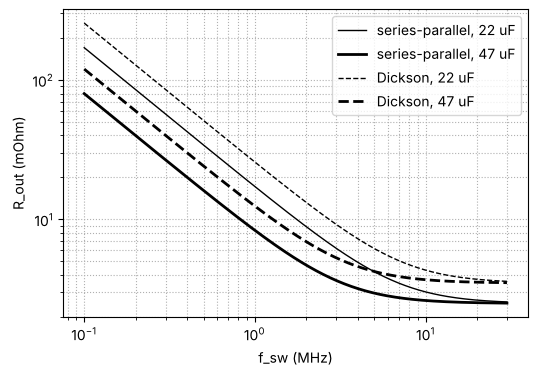

In [4]:
# Subtask 11.2.2 R_out versus frequency
fs = np.logspace(5, np.log10(3e7), 300)
plt.figure(figsize=(6, 4))
for name, ls in (('series-parallel 4:1', '-'), ('Dickson 4:1', '--')):
    for C0, lw in ((22e-6, 1.0), (47e-6, 2.0)):
        R = [get_Rout(res[name], C0, f, R_sw, derate)[2] for f in fs]
        plt.loglog(fs / 1e6, np.array(R) * 1e3, 'k' + ls, lw=lw, label=f'{name.split()[0]}, {C0*1e6:.0f} uF')
        Rssl, Rfsl, Rout = get_Rout(res[name], C0, f0, R_sw, derate)
        P = I_out**2 * Rout
        print(f"{name}, C0 = {C0*1e6:.0f} uF: R_out = {Rout*1e3:.2f} mOhm, loss = {P:.2f} W, "
              f"V_out = {12 - I_out*Rout:.3f} V, eta = {(12 - I_out*Rout)/12*100:.2f} %")
plt.xlabel('f_sw (MHz)'); plt.ylabel('R_out (mOhm)'); plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


### 11.2 Solution

$R_\mathrm{SSL}C_0f_\mathrm{sw} = 0.375$ (series-parallel) and $0.5625$ (Dickson): $39$ and $59~\mu\mathrm{F}$ nominal for $9.6~\mathrm{m\Omega}$ at $1~\mathrm{MHz}$. $R_\mathrm{FSL} = 2.5$ and $3.5~\mathrm{m\Omega}$, but the series-parallel converter needs switches for $36~\mathrm{V}$. At $1~\mathrm{MHz}$: $17.2/8.4~\mathrm{m\Omega}$ (series-parallel, 22/47 µF) and $25.8/12.5~\mathrm{m\Omega}$ (Dickson); efficiencies from charge sharing and conduction $98.2$ to $99.1~\%$ and $97.3$ to $98.7~\%$. Both are still in the SSL region; the corners lie at 3 to 7 MHz.


## 11.3 Resonant SC and flying-capacitor buck

11.3.1 2:1 resonant SC, $C = 10~\mu\mathrm{F}$, $500~\mathrm{kHz}$, $10~\mathrm{A}$, $5~\mathrm{m\Omega}$ per switch, $2~\mathrm{m\Omega}$ in the inductor: calculate $L_\mathrm{r}$, $Z_0$, the peak and rms currents and the losses; plot the inductor current over one period.

11.3.2 Inductance of a two-level and a three-level buck from $48~\mathrm{V}$ to $12~\mathrm{V}$ at $1~\mathrm{MHz}$ for $4~\mathrm{A}$ ripple; plot the normalised peak-to-peak ripple $\Delta i\,Lf_\mathrm{sw}/V_\mathrm{in}$ of both versus $D$.


L_r = 10.1 nH, Z0 = 31.8 mOhm, i_pk = 15.71 A, switch rms = 7.85 A
switches 1.23 W (FSL ideal 1.00 W, ratio 1.234), inductor 0.25 W, total 1.48 W


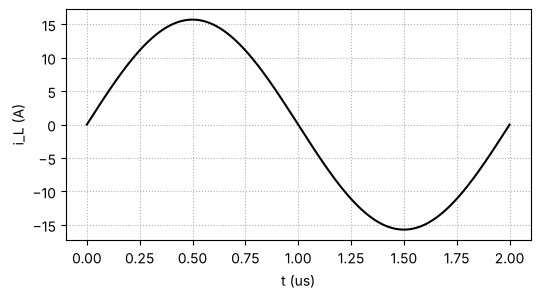

In [5]:
# Subtask 11.3.1 Resonant 2:1
C, fr, I, R, R_L = 10e-6, 500e3, 10.0, 5e-3, 2e-3
Lr = 1 / ((2 * np.pi * fr)**2 * C)
i_pk = np.pi / 2 * I
P_sw = 4 * (i_pk / 2)**2 * R                 # each switch: one half sine per period, rms = i_pk/2
P_L = (i_pk / np.sqrt(2))**2 * R_L           # inductor: |sin| over the whole period
P_fsl = 4 * (I / np.sqrt(2))**2 * R          # ideal FSL with constant currents
print(f"L_r = {Lr*1e9:.1f} nH, Z0 = {np.sqrt(Lr/C)*1e3:.1f} mOhm, i_pk = {i_pk:.2f} A, switch rms = {i_pk/2:.2f} A")
print(f"switches {P_sw:.2f} W (FSL ideal {P_fsl:.2f} W, ratio {P_sw/P_fsl:.3f}), inductor {P_L:.2f} W, total {P_sw+P_L:.2f} W")
t = np.linspace(0, 1 / fr, 400)
plt.figure(figsize=(6, 3))
plt.plot(t * 1e6, i_pk * np.sin(2 * np.pi * fr * t), 'k')
plt.xlabel('t (us)'); plt.ylabel('i_L (A)'); plt.grid(True, ls=':'); plt.show()


two-level: L = 2.25 uH, three-level: L = 0.75 uH, ratio 3.00


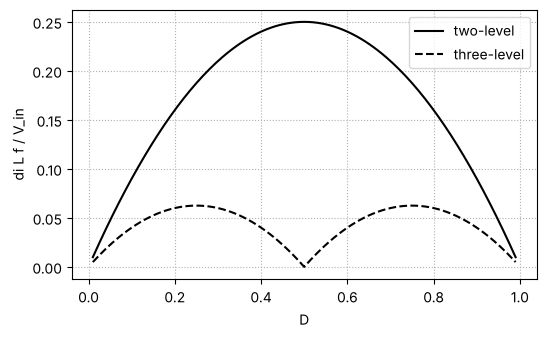

In [6]:
# Subtask 11.3.2 Two-level and three-level buck
Vin, Vo, fsw, di = 48.0, 12.0, 1e6, 4.0
D = Vo / Vin
L2 = Vin * D * (1 - D) / (fsw * di)
L3 = (Vin / 2 - Vo) * (2 * D) / (2 * fsw) / di
print(f"two-level: L = {L2*1e6:.2f} uH, three-level: L = {L3*1e6:.2f} uH, ratio {L2/L3:.2f}")


def ripple3(D):
    """normalised ripple di*L*f/Vin of the three-level buck (switch node 0..Vin/2 or Vin/2..Vin at 2 f)"""
    Dl = 2 * D - np.floor(2 * D)
    return 0.5 * Dl * (1 - Dl) / 2


Ds = np.linspace(0.01, 0.99, 197)
plt.figure(figsize=(6, 3.5))
plt.plot(Ds, Ds * (1 - Ds), 'k-', label='two-level')
plt.plot(Ds, ripple3(Ds), 'k--', label='three-level')
plt.xlabel('D'); plt.ylabel('di L f / V_in'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 11.3 Solution

$L_\mathrm{r} = 10.1~\mathrm{nH}$, $Z_0 = 32~\mathrm{m\Omega}$, peak $15.7~\mathrm{A}$, $7.85~\mathrm{A}$ rms per switch: $1.23~\mathrm{W}$ in the switches ($\pi^2/8$ times the ideal FSL), $0.25~\mathrm{W}$ in the inductor, about $1.5~\mathrm{W}$ against $5.1~\mathrm{W}$ hard-charged. Buck: $2.25~\mu\mathrm{H}$ (two-level) and $0.75~\mu\mathrm{H}$ (three-level), ratio 3 at $D = 0.25$; the maximum ripple of the three-level converter is a quarter of that of the two-level converter.
